# 06 · SVM

**Support Vector Machine (SVM)** busca el hiperplano que separa las clases con el mayor margen posible. Con TF-IDF (miles de
dimensiones y vectores dispersos) el **SVM lineal** (`LinearSVC`) suele ser de los mejores clasificadores de texto.

- `C` controla la regularización: `C` pequeño = margen amplio y modelo más simple; `C` grande = se ajusta más a los datos.
- `class_weight="balanced"`: los errores en la clase minoritaria (Envío) pesan más.
- Como opción adicional se prueba un **SVC con kernel RBF** (no lineal) con dos valores de `C`, para ver si la no linealidad ayuda.
  En la malla compiten ambos y `GridSearchCV` se queda con el de mejor F1 macro.

**Estructura del notebook** (igual para los 4 modelos, para que la comparación sea justa):
1. Cargar la partición fija (columna `particion`) y el texto preprocesado.
2. Definir el `Pipeline` TF-IDF + clasificador y la malla de hiperparámetros.
3. `GridSearchCV` con validación cruzada estratificada de 5 pliegues **solo sobre entrenamiento** (métrica: F1 macro).
4. Reentrenar con los mejores hiperparámetros y medir tiempos de entrenamiento y predicción.
5. Evaluar en prueba: accuracy, precisión, recall, F1 (macro, ponderado y por clase), matriz de confusión.
6. Guardar predicciones, métricas y el modelo (`joblib`).
7. Análisis de errores y palabras más influyentes.
8. Función para clasificar una reseña nueva.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC

import utils
from utils import CLASES, SEMILLA, RESULTADOS, MODELOS

NOMBRE = "SVM"
CLAVE = utils.MODELOS_PROYECTO[NOMBRE]          # nombre de carpeta / archivo
SALIDA = RESULTADOS / CLAVE                       # resultados/{clave}/
SALIDA.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)

# Partición fija generada en el notebook 02 (la misma para los 4 modelos)
df, entrenamiento, prueba = utils.cargar_particiones()
X_train, y_train = entrenamiento["texto_procesado"], entrenamiento["etiqueta_reglas"]
X_test, y_test = prueba["texto_procesado"], prueba["etiqueta_reglas"]

print(f"Entrenamiento: {len(X_train)} reseñas | Prueba: {len(X_test)} reseñas")
pd.DataFrame({"entrenamiento": y_train.value_counts(), "prueba": y_test.value_counts()}).reindex(CLASES)

Entrenamiento: 11860 reseñas | Prueba: 2966 reseñas


,entrenamiento,prueba
etiqueta_reglas,,
Envío,274,68
Producto,4613,1154
Sentimiento,6973,1744


## 1. Pipeline y malla de hiperparámetros

TF-IDF + SVM. Dos mallas: `LinearSVC` (varios `C`) y `SVC(kernel="rbf")` (dos `C`), ambas con `class_weight="balanced"`.

In [2]:
pipeline = Pipeline([
    ("tfidf", utils.crear_vectorizador()),
    ("clf", LinearSVC(class_weight="balanced", random_state=SEMILLA, max_iter=20000)),
])
malla = [
    {"clf": [LinearSVC(class_weight="balanced", random_state=SEMILLA, max_iter=20000)],
     "clf__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]},
    {"clf": [SVC(kernel="rbf", class_weight="balanced", gamma="scale", random_state=SEMILLA)],
     "clf__C": [1.0, 10.0]},
]
print("Combinaciones a evaluar:", sum(len(m["clf__C"]) for m in malla), "x 5 pliegues")

Combinaciones a evaluar: 8 x 5 pliegues


## 2. Búsqueda de hiperparámetros con validación cruzada (solo entrenamiento)

`GridSearchCV` prueba todas las combinaciones con **validación cruzada estratificada de 5 pliegues** (`random_state=42`) usando
**F1 macro** como criterio (también registra accuracy). Como el TF-IDF está dentro del `Pipeline`, en cada pliegue el vocabulario
se aprende solo con los datos de entrenamiento de ese pliegue: **no hay fuga de información**. El conjunto de prueba no se toca aquí.

In [3]:
busqueda, tiempo_busqueda = utils.buscar_hiperparametros(pipeline, malla, X_train, y_train)
print(f"Tiempo total de la búsqueda: {tiempo_busqueda:.1f} s")
print("Mejores hiperparámetros:", busqueda.best_params_)

cv = utils.resumen_cv(busqueda)
print(f"F1 macro en CV (5 pliegues): {cv['cv_f1_macro_media']:.4f} ± {cv['cv_f1_macro_std']:.4f}")
print(f"Accuracy en CV (5 pliegues): {cv['cv_accuracy_media']:.4f} ± {cv['cv_accuracy_std']:.4f}")

mejores, todas = utils.tabla_busqueda(busqueda)
todas.to_csv(SALIDA / "busqueda_hiperparametros.csv", index=False, encoding="utf-8-sig")
mejores.round(4)

Tiempo total de la búsqueda: 192.9 s
Mejores hiperparámetros: {'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 0.3}
F1 macro en CV (5 pliegues): 0.7115 ± 0.0126
Accuracy en CV (5 pliegues): 0.8178 ± 0.0045


,params,mean_test_f1_macro,std_test_f1_macro,mean_test_accuracy,std_test_accuracy,mean_fit_time,rank_test_f1_macro
0,"{'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 0.3}",0.7115,0.0126,0.8178,0.0045,3.3152,1
1,"{'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 0.1}",0.7048,0.0144,0.8034,0.0038,4.2316,2
2,"{'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 1.0}",0.7007,0.0166,0.8181,0.0046,4.0598,3
3,"{'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 3.0}",0.6958,0.0151,0.8122,0.0047,4.3753,4
4,"{'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 0.03}",0.6950,0.0200,0.7815,0.0066,3.6576,5
5,"{'clf': SVC(class_weight='balanced', random_state=42), 'clf__C': 10.0}",0.6624,0.0324,0.8198,0.0061,154.9489,6
6,"{'clf': LinearSVC(class_weight='balanced', max_iter=20000, random_state=42), 'clf__C': 0.01}",0.6572,0.0181,0.7548,0.0068,3.5433,7
7,"{'clf': SVC(class_weight='balanced', random_state=42), 'clf__C': 1.0}",0.6546,0.0321,0.8000,0.0057,97.3191,8


## 3. Reentrenar con los mejores hiperparámetros y medir tiempos

Se clona el mejor pipeline y se entrena de nuevo con **todo** el conjunto de entrenamiento, midiendo con `time.perf_counter()`:
- **Tiempo de entrenamiento:** ajuste del TF-IDF + clasificador.
- **Tiempo de predicción:** clasificar todas las reseñas de prueba.

Para que la comparación entre modelos sea justa, antes de medir se cierran los procesos auxiliares que dejó `GridSearchCV`
y la medición se repite **3 veces**, reportando la **mediana** (las predicciones son idénticas en cada repetición).

In [4]:
modelo = clone(busqueda.best_estimator_)
modelo, y_pred, t_entrenamiento, t_prediccion = utils.medir_entrenamiento_y_prediccion(modelo, X_train, y_train, X_test)
print(f"Tiempo de entrenamiento (mediana de 3): {t_entrenamiento:.3f} s")
print(f"Tiempo de predicción ({len(X_test)} reseñas): {t_prediccion:.3f} s "
      f"({1000 * t_prediccion / len(X_test):.3f} ms por reseña)")

Tiempo de entrenamiento (mediana de 3): 2.304 s
Tiempo de predicción (2966 reseñas): 0.199 s (0.067 ms por reseña)


## 4. Evaluación en el conjunto de prueba

In [5]:
metricas = utils.calcular_metricas(y_test, y_pred)
metricas.update(cv)
metricas.update({
    "tiempo_busqueda_s": tiempo_busqueda,
    "tiempo_entrenamiento_s": t_entrenamiento,
    "tiempo_prediccion_s": t_prediccion,
    "mejores_hiperparametros": {k: str(v) for k, v in busqueda.best_params_.items()},
})
metricas = utils.guardar_metricas(NOMBRE, metricas, SALIDA)
reporte = utils.guardar_reporte(NOMBRE, y_test, y_pred, metricas, SALIDA)
print(reporte)
print(f"Accuracy: {metricas['accuracy']:.4f} | F1 macro: {metricas['f1_macro']:.4f} | "
      f"F1 ponderado: {metricas['f1_ponderado']:.4f} | Errores: {metricas['n_errores']} de {metricas['n_prueba']}")

              precision    recall  f1-score   support

       Envío     0.6667    0.4412    0.5310        68
    Producto     0.7843    0.7721    0.7782      1154
 Sentimiento     0.8532    0.8733    0.8631      1744

    accuracy                         0.8240      2966
   macro avg     0.7681    0.6955    0.7241      2966
weighted avg     0.8221    0.8240    0.8225      2966

Accuracy: 0.8240 | F1 macro: 0.7241 | F1 ponderado: 0.8225 | Errores: 522 de 2966


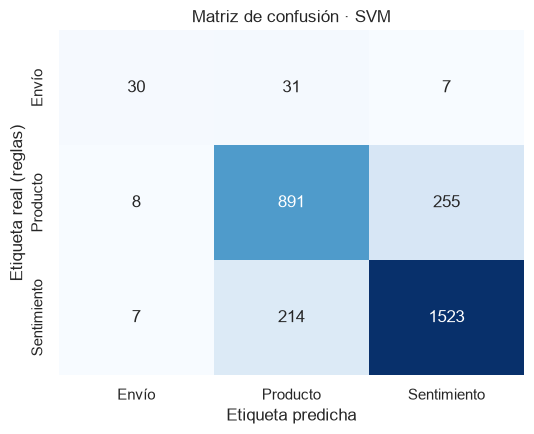

,pred_Envío,pred_Producto,pred_Sentimiento
real_Envío,30,31,7
real_Producto,8,891,255
real_Sentimiento,7,214,1523


In [6]:
matriz = utils.graficar_matriz_confusion(y_test, y_pred, f"Matriz de confusión · {NOMBRE}", SALIDA)
plt.show()
matriz

## 5. Guardar predicciones y modelo

- `predicciones_prueba.csv`: texto, estrellas, etiqueta real (reglas), etiqueta predicha, si acertó y la confianza por clase.
- `modelos/<modelo>.joblib`: el pipeline completo (TF-IDF + clasificador), listo para clasificar texto preprocesado.
- `mejores_hiperparametros.json`.

In [7]:
predicciones = utils.guardar_predicciones(prueba, y_pred, modelo, SALIDA)
joblib.dump(modelo, MODELOS / f"{CLAVE}.joblib")
with open(SALIDA / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump(metricas["mejores_hiperparametros"], f, ensure_ascii=False, indent=2)
print("Guardados:", (SALIDA / "predicciones_prueba.csv").relative_to(utils.BASE), "|",
      (MODELOS / f"{CLAVE}.joblib").relative_to(utils.BASE))
predicciones.head()

Guardados: resultados\svm\predicciones_prueba.csv | modelos\svm.joblib


,id,text,rating,polarity,etiqueta_real,etiqueta_predicha,correcta,confianza_Envío,confianza_Producto,confianza_Sentimiento
0,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B004OF968O_1493389988000,"Not for me..... I was not expecting much, but for me, these bags are a joke. I can't believe so many are still available, but impossible to find out who actually makes them. I wanted to make a s...",1.0,negative,Sentimiento,Producto,False,0.1417,0.5142,0.3440
1,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B00P9UC004_1521055721867,"Very small size. These are so small everything falls off. Too small for baseball caps, they just fall off. The pictures do not show the scale. Good if you want to hang a few rubber bands on hoo...",1.0,negative,Producto,Sentimiento,False,0.1729,0.4053,0.4218
2,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B081B65WT8_1591466996903,Did not work for me. I always have a problem when cooking pasta sauce on my glass stove top. I purchased a counter top induction burner and a new SS 16 qt stock pot along with this item. $$$$$ s...,2.0,negative,Producto,Producto,True,0.1625,0.5017,0.3358
3,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08G7Y67GH_1617298313281,UPDATE. Originally said this was a good deal....does the job.....bit after only three times with an egg one of the wires broke and hangs loose so now the slicer is useless. NOT a good deal and no...,1.0,negative,Producto,Producto,True,0.1374,0.7811,0.0815
4,AE2CJPQPEGCIDJKZZRYDSVRV46SA_B08NVKYLGV_1521054740535,"Should have sent it back...!!. I like the product just fine, but almost returned it because the large product label was so hard to remove, I ended up scratching the plastic. Now every time the lig...",2.0,negative,Producto,Producto,True,0.3158,0.4790,0.2052


## 6. Análisis de errores

### 6.1 ¿Qué confusiones son más frecuentes? Ejemplos reales

In [8]:
conteo_errores, ejemplos = utils.ejemplos_errores(predicciones, SALIDA, n_por_tipo=3)
display(conteo_errores)
for (real, pred), grupo in ejemplos.groupby(["etiqueta_real", "etiqueta_predicha"], sort=False):
    print(f"\n--- Real: {real}  ->  Predicha: {pred} ---")
    for _, fila in grupo.iterrows():
        print(f"  [{int(fila['rating'])}★] {fila['text']}")

,etiqueta_real,etiqueta_predicha,n_errores
0,Producto,Sentimiento,255
1,Sentimiento,Producto,214
2,Envío,Producto,31
3,Producto,Envío,8
4,Envío,Sentimiento,7
5,Sentimiento,Envío,7



--- Real: Producto  ->  Predicha: Sentimiento ---
  [5★] Works great. Works on chip bags!. Excellent product.  I haven't had it long to determine if it will last a long time but I love it.  I have 2 other foodsaver vacuum sealers, but so far this is my favorite.  One of the thingsI love most about it, is the onboard vacuum hose which can be used for jars.
  [4★] Small and .... My wife wishes she had read this closer. She expected them to be ready to give as a gift not require embroidery. they were a bit too small too.
  [3★] It's OK. Good deal for the price, but not my favorite coffee pot. It's cheaply constructed and a pain to pour the water in.  I like the pot-less option.  I purchased this as a quick replacement for my last, more expensive, single pour pot because this had the &#34;bold&#34; option.  I find very litt

--- Real: Sentimiento  ->  Predicha: Producto ---
  [2★] One Major Flaw. It produced a good amount of steam quickly and for a long time.  I was working on polyester, 

### 6.2 ¿Se clasifican peor las reseñas de 3 estrellas (neutral)?

In [9]:
por_polaridad = utils.desempeno_por_polaridad(predicciones, SALIDA)
por_polaridad.round(4)

,polaridad,n,accuracy,f1_macro
0,negative,955,0.8031,0.7253
1,neutral,1022,0.7661,0.6646
2,positive,989,0.9039,0.7432


### 6.3 Palabras más influyentes por clase

En el SVM lineal cada clase tiene un vector de **coeficientes** (esquema uno contra el resto): un coeficiente positivo grande
significa que la palabra empuja la reseña hacia esa clase. Si la búsqueda hubiera elegido el kernel RBF (que no tiene
coeficientes por palabra), se entrena un `LinearSVC` auxiliar solo para interpretar.

In [10]:
tfidf, svm_clf = modelo.named_steps["tfidf"], modelo.named_steps["clf"]
if not hasattr(svm_clf, "coef_") or getattr(svm_clf, "kernel", "linear") != "linear":
    print("El mejor SVM no es lineal; se usa un LinearSVC auxiliar solo para interpretar.")
    svm_clf = LinearSVC(class_weight="balanced", random_state=SEMILLA, max_iter=20000).fit(
        tfidf.transform(X_train), y_train)
vocabulario = tfidf.get_feature_names_out()
pesos = svm_clf.coef_.toarray() if hasattr(svm_clf.coef_, "toarray") else svm_clf.coef_
influyentes = utils.palabras_influyentes_lineales(pesos, vocabulario, svm_clf.classes_, n=15)
influyentes.to_csv(SALIDA / "palabras_influyentes.csv", index=False, encoding="utf-8-sig")
influyentes

,Envío,Producto,Sentimiento
0,arrive (3.39),not work (4.74),no (0.98)
1,packaging (2.52),break (4.18),perfect (0.95)
2,deliver (2.36),smell (4.11),great (0.95)
3,damage (2.30),flimsy (3.73),love (0.90)
4,come (2.10),not fit (3.62),small think (0.82)
5,come broken (2.10),useless (3.17),perfectly (0.72)
6,broken (2.09),leak (3.09),not big (0.72)
7,receive (1.88),not hold (2.88),five star (0.67)
8,package (1.85),not stay (2.82),nice (0.67)
9,arrive broken (1.83),not easy (2.43),not flimsy (0.67)


## 7. Clasificar una reseña nueva

La reseña se preprocesa exactamente igual que en el entrenamiento (`utils.preprocesar_texto`) y luego pasa por el pipeline
(TF-IDF + clasificador).

In [11]:
def clasificar_texto(texto):
    procesado = utils.preprocesar_texto(texto)
    confianzas, tipo = utils.puntajes_confianza(modelo, [procesado])
    etiqueta = modelo.predict([procesado])[0]
    detalle = {c: round(float(p), 3) for c, p in zip(modelo.classes_, confianzas[0])}
    return etiqueta, detalle

for resena in ["The box arrived crushed and two glasses were broken.",
               "The blender stopped working after a week, the motor smells like burning.",
               "Absolutely love these towels, they are soft and beautiful!"]:
    etiqueta, detalle = clasificar_texto(resena)
    print(f"{etiqueta:12s} {detalle}  <-  {resena}")

Envío        {'Envío': 0.511, 'Producto': 0.357, 'Sentimiento': 0.132}  <-  The box arrived crushed and two glasses were broken.
Producto     {'Envío': 0.032, 'Producto': 0.937, 'Sentimiento': 0.031}  <-  The blender stopped working after a week, the motor smells like burning.
Sentimiento  {'Envío': 0.082, 'Producto': 0.115, 'Sentimiento': 0.803}  <-  Absolutely love these towels, they are soft and beautiful!
